<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/colab/GEMS_P6_RECOVERY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GEMS P6.1 — Performance Recovery & Structural Fault Discovery | Colab CPU (high-RAM)

Standalone runner for `gems_bench/p6/boost_diagnostics.py` (P6.1). It **reuses** the frozen W2 model, its sampled rows, its held-out and full-region maps, the M9 baseline context, the B0/B1 maps and the P6 boost benchmark from `MyDrive/GEMS_2`. It does **not** rerun W0–W2, M9, G01/G02 research or W3, and it never uploads a submission.

**Order:** 0 config → 1 Drive + strict clone → 2 artifact attachment + preflight → 3 X1 export parity → 4 X2 candidate recall → 5 X3 segment recovery → 6 X4 G01/G02 audit (+ explicit backfill, S1) → 7 X5 robustness → 8 selection → 9 export (OFF) → 10 report + Drive sync.

Every stage writes `outputs/p6_fast_track/recovery/<stage>/{manifest,status,decision}.json`, CSV / Parquet tables and PNG figures with their plot data. A stage whose fingerprint and outputs are unchanged reloads instead of recomputing, so after a Colab disconnect re-run sections 0–2 and continue. Nothing in this notebook has been executed by the authoring session: every number comes from your Colab run. Docs: `docs/p6/P6_RECOVERY_HANDOFF.md`.

## 0 — Configuration (edit before running)

First run: `preflight`, `export_parity`, `candidate_recall`, `report` only. `CONFIG['ref']` must resolve to the pushed P6.1 commit (pin the SHA in `EXPECT['commit']`); a missing branch is an error, never a silent fallback to `main`.

In [1]:
CONFIG = {
    'repo': 'mybenkhadda/GEMS---drivendata',
    'ref': 'main',  # Prefer exact pushed commit SHA
    'drive_root': '/content/drive/MyDrive/GEMS_2',
    'local_root': '/content/gems_work',

    'run_mode': 'PREPARE_DATA',
    'failure_policy': 'interactive',
    'download_missing': False,

    'run_advanced_models': False,
    'train_baselines': [],
    'run_full_inference': False,
    'run_submission': False,

    'feature_stage': 'lazy',
    'use_gpu': True,
    'seed': 2026,
}

PRIVATE_REPO = False

DEM_CONFIG = {
    'enabled': False,
    'mode': 'inventory_only',
    'download': False,
}

M9_CONFIG = {
    'profile': 'PILOT',
    'overwrite_existing': False,
}

P6_CONFIG = {
    'overwrite_existing': False,
}

BOOST_CONFIG = {
    'geology': {
        'backfill_missing': False,
    }
}

RECOVERY_CONFIG = {}

RECOVERY_RUN = {
    'preflight': True,
    'export_parity': True,
    'candidate_recall': True,
    'segment_recovery': True,
    'g02_repair_audit': True,
    'g02_backfill': False,
    'geology': False,
    'robustness': True,
    'selection': True,
    'export': False,
    'report': True,
}

RECOVERY_EXPORT = {
    'candidate_fp': None,
}

EXPECT = {
    'notebook_version': 'p6r-nb.1',
    'code_rev': 'p6b.1-r3',
    'recovery_code_rev': 'p6r.1-r1',
    'commit': None,
}

## 1 — Google Drive, strict repository clone, version lock

In [2]:
import base64, os, subprocess, sys
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
CODE = '/content/GEMS'
REPO_URL = f"https://github.com/{CONFIG['repo']}.git"

def _git_env():
    if not PRIVATE_REPO:
        return None
    from google.colab import userdata
    token = userdata.get('GITHUB_TOKEN') or ''
    if not token:
        raise RuntimeError('PRIVATE_REPO=True but GITHUB_TOKEN is missing in Colab Secrets')
    hdr = base64.b64encode(f'x-access-token:{token}'.encode()).decode()
    return {**os.environ, 'GIT_CONFIG_COUNT': '1', 'GIT_CONFIG_KEY_0': 'http.https://github.com/.extraheader',
            'GIT_CONFIG_VALUE_0': f'AUTHORIZATION: basic {hdr}'}

def git(*args, auth=False, check=True):
    r = subprocess.run(['git', *args], capture_output=True, text=True, env=_git_env() if auth else None)
    if check and r.returncode:
        raise RuntimeError(f"git {' '.join(args[:4])} failed:\n{r.stderr[-1500:]}")
    return r

if not Path(CODE, '.git').exists():
    git('clone', '-q', REPO_URL, CODE, auth=True)
git('-C', CODE, 'remote', 'set-url', 'origin', REPO_URL)
git('-C', CODE, 'fetch', '-q', '--tags', 'origin', auth=True)
ref = CONFIG['ref']
if git('-C', CODE, 'rev-parse', '--verify', '-q', f'refs/remotes/origin/{ref}', check=False).returncode == 0:
    git('-C', CODE, 'checkout', '-q', '-B', 'p6r_colab_active', f'origin/{ref}')
else:                                   # a SHA / tag must resolve; never fall back to main
    git('-C', CODE, 'checkout', '-q', '--detach', ref)
HEAD = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
if 'gems_bench' in sys.modules:
    raise RuntimeError('gems_bench already imported: restart the runtime (stale module code)')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', f'{CODE}[colab]'], check=True)
if CODE not in sys.path:
    sys.path.insert(0, CODE)
os.environ['GEMS_CODE_COMMIT'] = HEAD
print('Requested:', ref, '| resolved SHA:', HEAD)


Mounted at /content/drive
Requested: main | resolved SHA: acbc694b8e478a78b1db037d3c364ea8933e3ff0


In [3]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from gems_bench.p6.boost_diagnostics import startup_check
START = startup_check(CONFIG['ref'], HEAD,
                      {**EXPECT, 'code_root': CODE,
                       'artifact_root': f"{CONFIG['drive_root']}/outputs/p6_fast_track/recovery"},
                      BOOST_CONFIG, RECOVERY_CONFIG)
print(json.dumps(START, indent=2, default=str))


{
  "requested_ref": "main",
  "resolved_commit": "acbc694b8e478a78b1db037d3c364ea8933e3ff0",
  "installed_commit": "acbc694b8e478a78b1db037d3c364ea8933e3ff0",
  "boost_module": "/content/GEMS/gems_bench/p6/boost.py",
  "boost_code_rev": "p6b.1-r3",
  "boost_version": "p6b.1",
  "boost_config_fp": "2f973e4709ae",
  "notebook_version": "p6r-nb.1",
  "artifact_root": "/content/drive/MyDrive/GEMS_2/outputs/p6_fast_track/recovery",
  "problems": [],
  "recovery_code_rev": "p6r.1-r1",
  "recovery_config_fp": "798818960ec3"
}


## 2 — Artifact attachment (no retraining) + preflight

Reuses the M9 baseline context, B0/B1 maps, the frozen W2 candidate / rows / maps (`stack/`), `stack/maps/full_score.tif` and the boost benchmark (`boost/benchmark/`). Missing W2 inputs stop here: do **not** regenerate W2 in this notebook.

In [4]:
from gems_bench.pipeline import Pipeline
from gems_bench.p6 import P6FastTrack

pipe = Pipeline.from_notebook(CONFIG, DEM_CONFIG)
pipe.step('bootstrap')
for step in ('raw_data', 'native_grid', 'spatial_folds', 'discovery_splits', 'feature_store'):
    pipe.step(step)                     # validate + stage cached Drive data, never rebuild
m9 = pipe.m9(M9_CONFIG)
m9.load()
p6 = P6FastTrack(m9, P6_CONFIG)
rc = p6.recovery(RECOVERY_CONFIG, BOOST_CONFIG)
bst = rc.bst
need = bst.stage()                      # stack/, boost/, submissions/, manifests/ from Drive
p6.m9.stage_in([f"{p6.cfg['output_dir']}/{rc.cfg['subdir']}"])   # earlier recovery outputs (resume)
missing = [k for k in ('stack/candidate.json', 'stack/features/rows.parquet') if not need.get(k)]
if need.get('stack/maps/*.npy', 0) != 6:
    missing.append(f"stack/maps/*.npy expected 6, got {need.get('stack/maps/*.npy', 0)}")
if missing:
    raise RuntimeError('Frozen W2 artifacts missing: ' + ', '.join(missing) + ' (restore them on Drive; W2 is not rerun)')
print('Recovery root:', rc.root)
print('Champion:', json.dumps(bst.champion(), indent=2, default=str))
display(p6.budget.table())


[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/bootstrap.json']
[bootstrap] DONE: bootstrap: ok (3 checks)
[bootstrap] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/config_snapshot.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/environment_report.csv']
[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/raw_data.json']
[raw_data] DONE: raw_data: ok (3 checks)
[raw_data] outputs: ['/content/drive/MyDrive/GEMS_2/data/raw/acquisition_manifest.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/raw_data_acquisition.csv']
[sync in] 1 copied (0.0 MiB), 0 unchanged, 1s: ['environment/pipeline/native_grid.json']
[native_grid] SKIP_CACHED: native_g

,workstream,device,cap_h,spent_h,left_h
0,w0,gpu,0.0,0.000,0.000
1,w0,cpu,0.5,0.016,0.484
2,w1,gpu,4.0,0.000,4.000
3,w1,cpu,1.5,0.000,1.500
4,w2,gpu,0.0,0.000,0.000
5,w2,cpu,6.0,0.261,5.739
6,w3,gpu,2.0,0.000,2.000
7,w3,cpu,0.5,0.000,0.500
8,w4,gpu,0.0,0.000,0.000
9,w4,cpu,6.0,0.000,6.000


In [5]:
if RECOVERY_RUN['preflight']:
    pre = rc.preflight()
    print(json.dumps(pre['ready'], indent=2))
    print('Failed checks:', pre['failed_checks'])
    display(rc.load_table('dependency_check', 'preflight'))
    if not pre['ready']['candidate_recall']:
        print('STOP: core inputs missing (boost stage A must be complete; run the boost notebook A cell first).')


[sync in] 333 copied (4168.4 MiB), 0 unchanged, 376s: ['cache/m9/layers', 'outputs/m9_geofault_production/research/G01_wavelet_geology', 'outputs/m9_geofault_production/research/G02_structural_geology']
[g02] attached g02_23686a63cb (explicit run_id); unit rasters: ['disc_official_0', 'disc_official_1', 'geo_0', 'geo_1']
[sync out] 89 copied (341.2 MiB), 0 unchanged, 5s: ['outputs/p6_fast_track']
[sync out] 2 copied (0.0 MiB), 88 unchanged, 0s: ['outputs/p6_fast_track']
{
  "export_parity": true,
  "export_parity_tables_only": true,
  "candidate_recall": true,
  "segment_recovery": true,
  "geology_audit": true,
  "g02_backfill": false,
  "export": false
}
Failed checks: ['RAM available GB', 'G02 rasters for every unit']


,kind,name,ok,sha256,detail
0,python_module,numpy,True,NaN,NaN
1,python_module,scipy,True,NaN,NaN
2,python_module,pandas,True,NaN,NaN
3,python_module,pyarrow,True,NaN,NaN
4,python_module,rasterio,True,NaN,NaN
5,python_module,matplotlib,True,NaN,NaN
6,python_module,lightgbm,True,NaN,NaN
7,python_module,joblib,True,NaN,NaN
8,python_module,skimage,True,NaN,NaN
9,python_module,psutil,True,NaN,NaN


## 3 — X1: deployable W2 policies and export parity

Policies A–E (+ fallback reference) re-evaluated from the saved boost grid: for each outer zone ONE cell is chosen on non-overlapping zones under the predeclared objective (`disc_geo_floor`) and applied to the same zone in **both** tasks. `separate` rows reproduce the boost numbers (disc and geo selected independently; flagged not deployable when the cells differ). `META` is the honest estimate of choosing the policy itself. Parity compares the training construction with the full-region (inference) construction.

[sync in] 1 copied (0.0 MiB), 0 unchanged, 1s: ['outputs/m9_geofault_production/baseline/baseline_selection.json']
[sync in] 7 copied (48.7 MiB), 0 unchanged, 11s: ['reports/gems3/predictions']
[sync out] 15 copied (0.3 MiB), 90 unchanged, 0s: ['outputs/p6_fast_track']
[sync out] 2 copied (0.0 MiB), 104 unchanged, 0s: ['outputs/p6_fast_track']


,policy,objective,role,deployable,disc_dti,disc_worst,disc_worst_zone,geo_dti,systems_gained,systems_lost,reproduces_benchmark,deploy_cell
0,A_w2_original,disc,deploy_candidate,True,0.224640,0.153414,2,0.102664,4,1,NaN,"{""candidate"": ""w2"", ""blend"": 1.0, ""rep"": ""skel..."
1,B_w2_crest,disc,deploy_candidate,True,0.238882,0.192575,2,0.114259,6,0,NaN,"{""candidate"": ""w2"", ""blend"": 1.0, ""rep"": ""cres..."
2,C_w2_skeleton,disc,deploy_candidate,True,0.242156,0.198579,2,0.105687,5,1,NaN,"{""candidate"": ""w2"", ""blend"": 1.0, ""rep"": ""skel..."
3,D_w2_rep_frac,disc,deploy_candidate,True,0.242156,0.198579,2,0.105687,5,1,NaN,"{""candidate"": ""w2"", ""blend"": 1.0, ""rep"": ""skel..."
4,E_w2_uploaded_cell,disc,historical,True,0.178905,0.155761,2,0.168841,38,0,NaN,"{""candidate"": ""w2"", ""blend"": 1.0, ""rep"": ""skel..."
5,R_fallback_fusion,disc,reference,True,0.162482,0.126160,2,0.158416,0,0,NaN,"{""candidate"": ""fallback_fusion"", ""blend"": 0.0,..."
6,A_w2_original,disc_geo_floor,deploy_candidate,True,0.187338,0.163983,2,0.186103,19,1,NaN,"{""candidate"": ""hybrid"", ""blend"": 0.5, ""rep"": ""..."
7,B_w2_crest,disc_geo_floor,deploy_candidate,True,0.174282,0.154489,2,0.186047,11,4,NaN,"{""candidate"": ""w2"", ""blend"": 1.0, ""rep"": ""cres..."
8,C_w2_skeleton,disc_geo_floor,deploy_candidate,True,0.206651,0.184673,1,0.132302,13,9,NaN,"{""candidate"": ""w2"", ""blend"": 1.0, ""rep"": ""skel..."
9,D_w2_rep_frac,disc_geo_floor,deploy_candidate,True,0.174228,0.154489,2,0.180350,17,3,NaN,"{""candidate"": ""w2"", ""blend"": 1.0, ""rep"": ""cres..."


Chosen: C_w2_skeleton | objective: disc | verdict: FAIL
META (choose policy, nested): {"policy": "META", "objective": "disc", "geo_dti": 0.10266401075515341, "geo_worst": 0.08691096566601164, "disc_dti": 0.22464028846915302, "disc_worst": 0.1534143947207408, "chosen_per_zone": {"0": "C_w2_skeleton", "1": "C_w2_skeleton", "2": "A_w2_original"}}
Plan audit: PASS | parity BLOCKED rows: [{'unit': 'geo:0', 'feature': 'w2_score'}, {'unit': 'geo:0', 'feature': 'cnn_disagree'}, {'unit': 'geo:1', 'feature': 'w2_score'}, {'unit': 'geo:2', 'feature': 'w2_score'}, {'unit': 'geo:2', 'feature': 'cnn_disagree'}, {'unit': 'disc_official:0', 'feature': 'cnn_b0'}, {'unit': 'disc_official:0', 'feature': 'cnn_b1'}, {'unit': 'disc_official:0', 'feature': 'cnn_disagree'}, {'unit': 'disc_official:1', 'feature': 'cnn_b0'}, {'unit': 'disc_official:1', 'feature': 'cnn_b1'}, {'unit': 'disc_official:1', 'feature': 'cnn_disagree'}, {'unit': 'disc_official:2', 'feature': 'cnn_b0'}, {'unit': 'disc_official:2', 'feat

,check,status,rows
0,feature,BLOCKED,11
1,feature,PASS,30
2,feature,WARNING,25
3,fusion_weight,PASS,6
4,map_agreement,WARNING,6
5,w2_score,BLOCKED,3
6,w2_score,WARNING,3


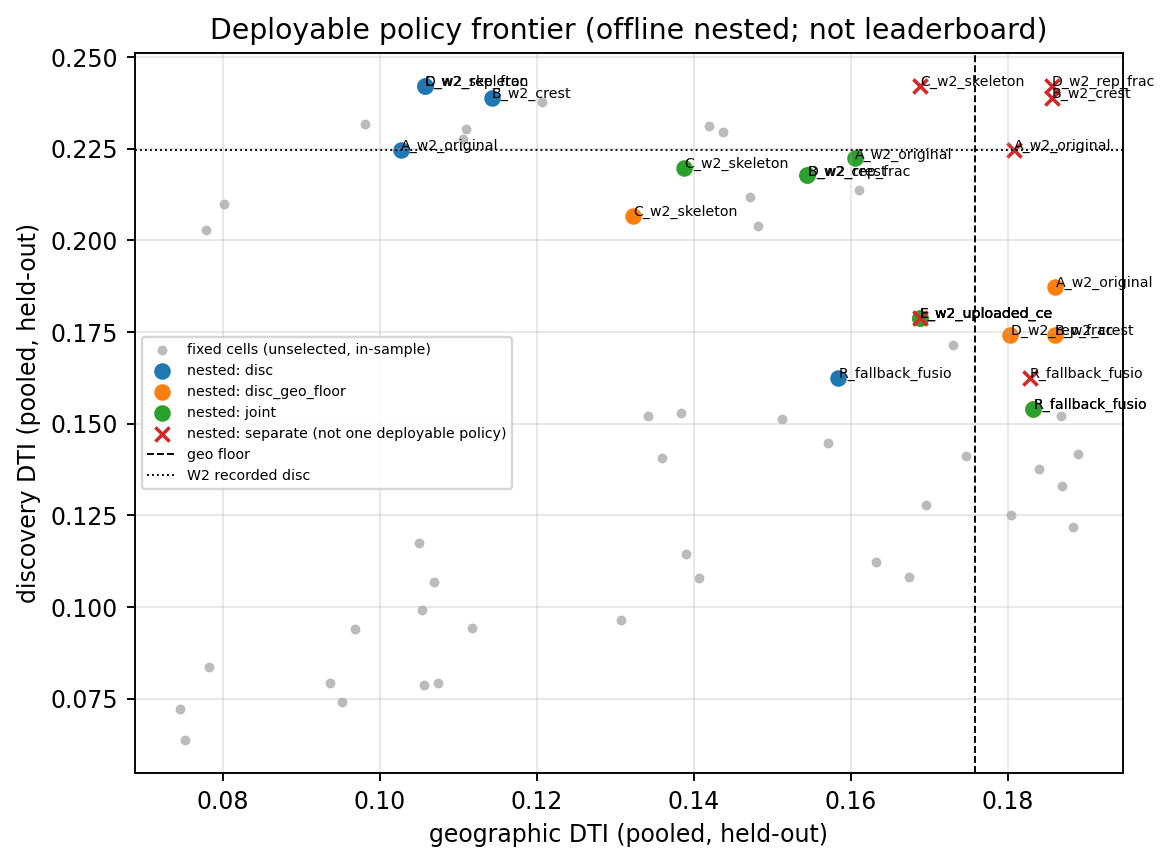

In [6]:
if RECOVERY_RUN['export_parity']:
    x1 = rc.export_parity()
    d = x1['decision']
    cols = ['policy', 'objective', 'role', 'deployable', 'disc_dti', 'disc_worst', 'disc_worst_zone', 'geo_dti',
            'systems_gained', 'systems_lost', 'reproduces_benchmark', 'deploy_cell']
    C = x1['policy_comparison']
    display(C[[c for c in cols if c in C]])
    print('Chosen:', d['chosen_policy'], '| objective:', d['objective'], '| verdict:', d['verdict'])
    print('META (choose policy, nested):', json.dumps(d['meta_nested'], default=str))
    print('Plan audit:', d['plan_status'], '| parity BLOCKED rows:', d['parity_blocked'])
    P = x1['train_inference_parity']
    display(P.groupby(['check', 'status']).size().rename('rows').reset_index())
    display(Image(filename=str(rc.root / 'export_parity' / 'policy_frontier.png')))


## 4 — X2: candidate-pool recall ceiling

Reachable systems per source and budget, the inventory union, the **oracle** (held-out labels pick pool segments: a diagnostic upper bound only, never used for selection) and the failure taxonomy with its threshold sensitivity. Reference annotations in the figures are evaluation-only.

/content/GEMS/gems_bench/p6/candidate_recall.py:509: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "fallback-only": TX[rb.str.contains("fallback_fusion") & ~rb.str.contains(r"(^|;)w2(;|$)")],
/content/GEMS/gems_bench/p6/candidate_recall.py:510: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "W2-only": TX[rb.str.contains(r"(^|;)w2(;|$)") & ~rb.str.contains("fallback_fusion")],


[sync out] 18 copied (3.9 MiB), 106 unchanged, 0s: ['outputs/p6_fast_track']
[sync out] 2 copied (0.0 MiB), 123 unchanged, 0s: ['outputs/p6_fast_track']
Verdict: RANKING | dominant: ranking | next: feature engineering and ranker improvement (label-safe structural evidence, bounded experiments)
Shares by length: {"geometry": 0.17096922899619682, "ranking": 0.8290307710038032}


,displaced_factor,support_low,verdict,dominant_group,share_by_length
0,1.5,0.025,RANKING,ranking,"{'geometry': 0.17096922899619682, 'ranking': 0..."
1,1.5,0.050,RANKING,ranking,"{'geometry': 0.17096922899619682, 'ranking': 0..."
2,1.5,0.100,RANKING,ranking,"{'geometry': 0.17096922899619682, 'ranking': 0..."
3,2.0,0.025,RANKING,ranking,"{'geometry': 0.17096922899619682, 'ranking': 0..."
4,2.0,0.050,RANKING,ranking,"{'geometry': 0.17096922899619682, 'ranking': 0..."
5,2.0,0.100,RANKING,ranking,"{'geometry': 0.17096922899619682, 'ranking': 0..."
6,3.0,0.025,RANKING,ranking,"{'geometry': 0.17096922899619682, 'ranking': 0..."
7,3.0,0.050,RANKING,ranking,"{'geometry': 0.17096922899619682, 'ranking': 0..."
8,3.0,0.100,RANKING,ranking,"{'geometry': 0.17096922899619682, 'ranking': 0..."


,source,rep,frac,dti,system_recall,length_weighted_recall,completely_missed
0,cnn_b0,crest_1px,0.005,0.117435,0.041667,0.056785,61.0
1,cnn_b0,crest_1px,0.010,0.152243,0.116667,0.157456,28.0
2,cnn_b0,crest_1px,0.015,0.151256,0.158333,0.215181,13.0
3,cnn_b0,crest_1px,0.030,0.141180,0.241667,0.279221,4.0
4,cnn_b0,crest_1px,0.050,0.125050,0.358333,0.451008,0.0
...,...,...,...,...,...,...,...
115,w2_fallback_union,skeleton_1px,0.005,0.097313,NaN,NaN,NaN
116,w2_fallback_union,skeleton_1px,0.010,0.122903,NaN,NaN,NaN
117,w2_fallback_union,skeleton_1px,0.015,0.138556,NaN,NaN,NaN
118,w2_fallback_union,skeleton_1px,0.030,0.168858,NaN,NaN,NaN


,frac,existing_ranker_nested_disc_dti,existing_note,best_fixed_source_cell_dti,best_fixed_source_cell,best_fixed_note,union_system_recall,oracle_constrained_dti,oracle_note,oracle_unconstrained_dti
0,0.005,0.242156,X1 chosen deployable policy (nested; its own b...,0.238882,w2|crest_1px,in-sample max over sources and reps (diagnosti...,0.191667,0.223149,held-out labels choose pool segments within th...,NaN
1,0.010,0.242156,X1 chosen deployable policy (nested; its own b...,0.242156,w2|skeleton_1px,in-sample max over sources and reps (diagnosti...,0.250000,0.223149,held-out labels choose pool segments within th...,NaN
2,0.015,0.242156,X1 chosen deployable policy (nested; its own b...,0.237648,w2|skeleton_1px,in-sample max over sources and reps (diagnosti...,0.308333,0.223149,held-out labels choose pool segments within th...,NaN
3,0.030,0.242156,X1 chosen deployable policy (nested; its own b...,0.211884,w2|skeleton_1px,in-sample max over sources and reps (diagnosti...,0.575000,0.223149,held-out labels choose pool segments within th...,NaN
4,0.050,0.242156,X1 chosen deployable policy (nested; its own b...,0.178905,w2|skeleton_1px,in-sample max over sources and reps (diagnosti...,0.791667,0.223149,held-out labels choose pool segments within th...,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unconstrained diagnostic bound: every truth-to...,0.223149


,category,systems
0,budget_limitation,53
1,fragmented,23
2,ranked_too_low,24
3,recovered,20


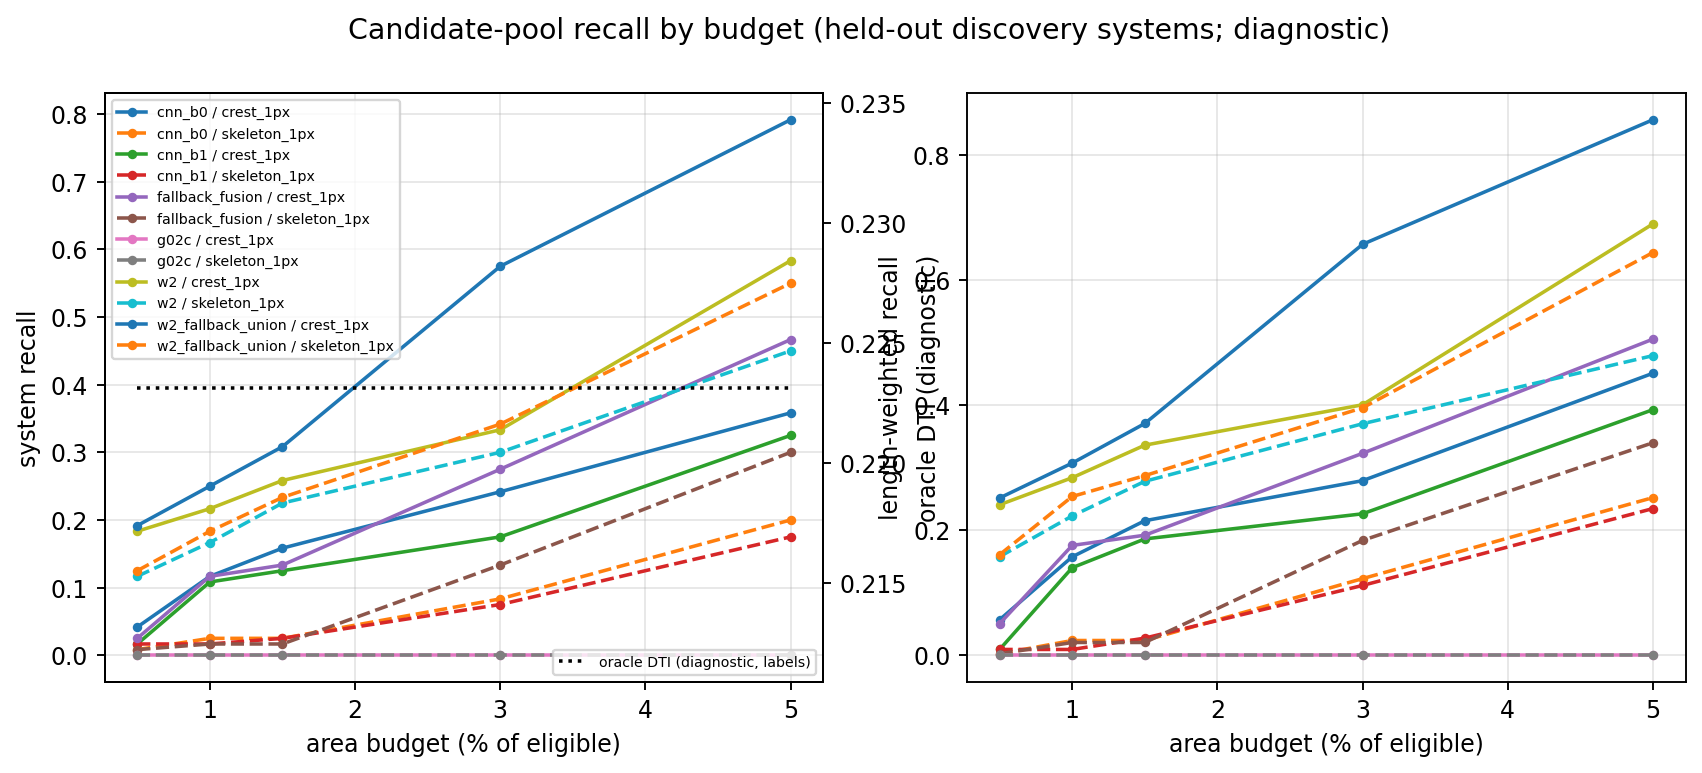

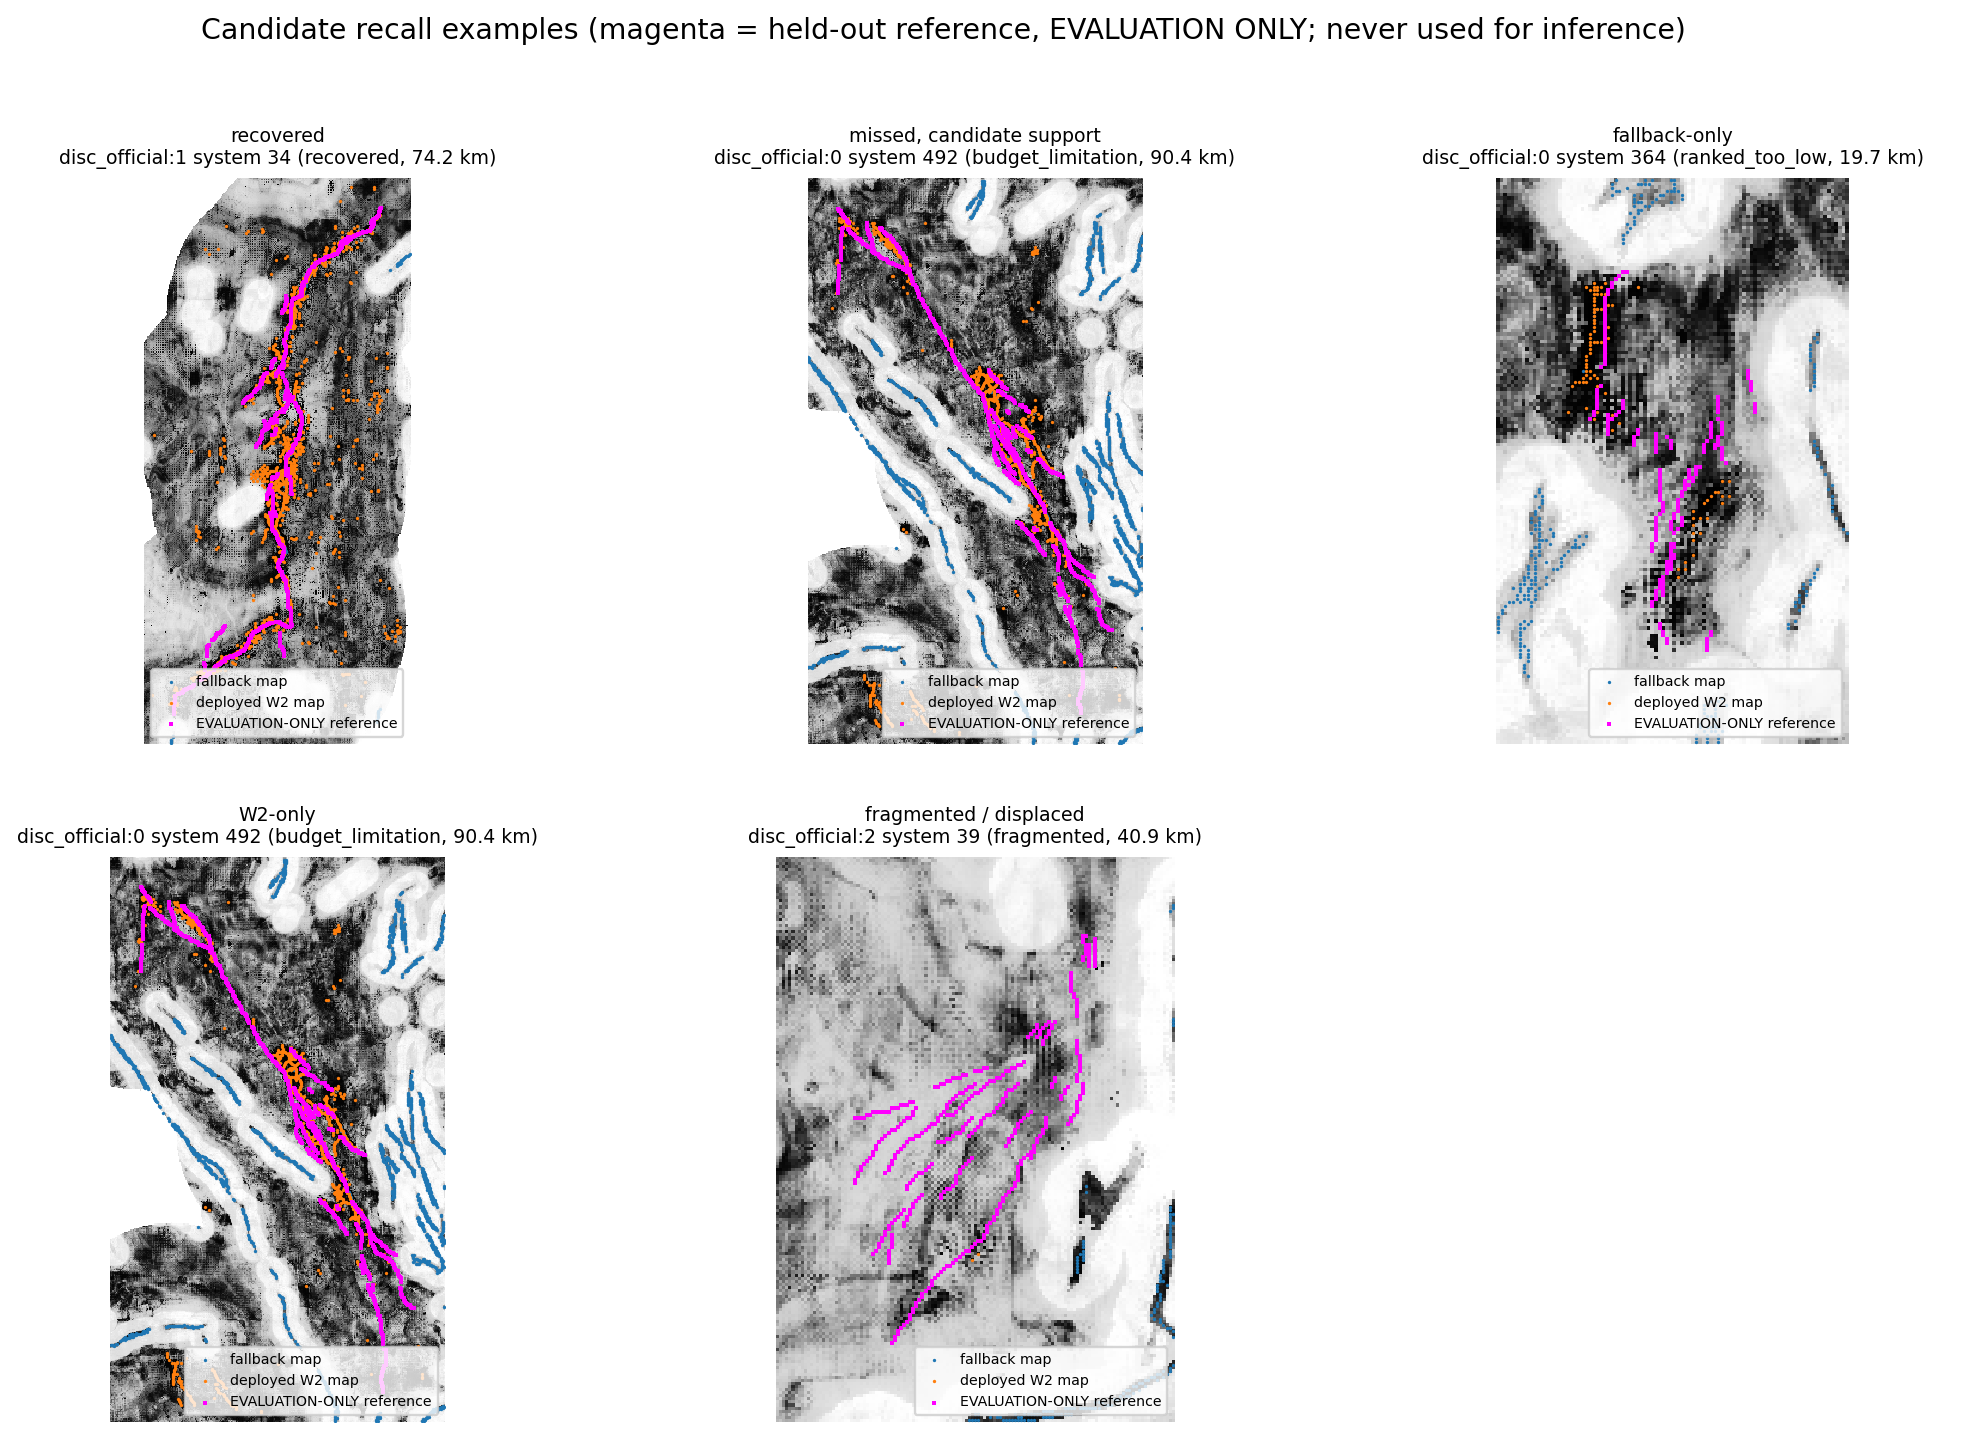

In [7]:
if RECOVERY_RUN['candidate_recall']:
    x2 = rc.candidate_recall()
    d = x2['decision']
    print('Verdict:', d.get('verdict'), '| dominant:', d.get('dominant_group'), '| next:', d.get('next_direction'))
    print('Shares by length:', json.dumps(d.get('share_by_length'), default=str))
    display(pd.DataFrame(d.get('sensitivity') or []))
    cb = x2['coverage_by_budget']
    display(cb[[c for c in ('source', 'rep', 'frac', 'dti', 'system_recall', 'length_weighted_recall',
                           'completely_missed') if c in cb]])
    display(x2['oracle_upper_bound'])
    display(x2['missed_system_taxonomy'].groupby('category').size().rename('systems').reset_index())
    display(Image(filename=str(rc.root / 'candidate_recall' / 'coverage_curves.png')))
    display(Image(filename=str(rc.root / 'candidate_recall' / 'missed_system_examples.png')))


## 5 — X3: segment-level recovery (explicit)

H0 pure W2, H1 confident fallback-only additions, H2 graph-supported additions — all at the area of the H0 cell. A strategy that only adds systems without a nested DTI gain (or with a worst-zone / FP regression) is REJECTED.

[sync out] 15 copied (23.2 MiB), 125 unchanged, 1s: ['outputs/p6_fast_track']
[sync out] 2 copied (0.0 MiB), 139 unchanged, 0s: ['outputs/p6_fast_track']


,candidate,decision,disc_dti,disc_worst,geo_dti,systems_gained,systems_lost,fp_increase,length_km,reasons
0,H0,BASE,0.242156,0.198579,0.105687,0,0,0.000000,2458.5,NaN
1,H1,REJECT,0.223435,0.180706,0.113396,1,4,0.143089,2654.0,disc 0.2234 not above base 0.2422 + 0.000; wor...
2,H2,REJECT,0.239703,0.191037,0.106195,3,1,0.109472,2652.2,disc 0.2397 not above base 0.2422 + 0.000; wor...


Budget violations: 0 | chosen: H0


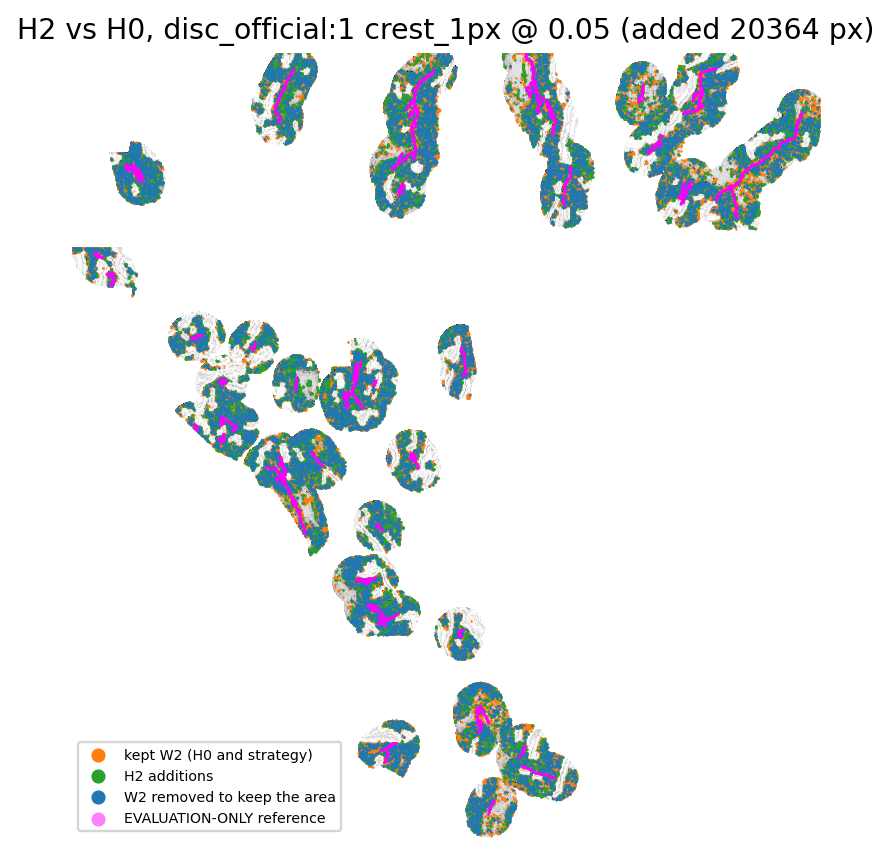

In [8]:
if RECOVERY_RUN['segment_recovery']:
    x3 = rc.segment_recovery()
    H = x3['hybrid_comparison']
    display(H[[c for c in ('candidate', 'decision', 'disc_dti', 'disc_worst', 'geo_dti', 'systems_gained',
                           'systems_lost', 'fp_increase', 'length_km', 'reasons') if c in H]])
    print('Budget violations:', x3['decision']['budget_violations'], '| chosen:', x3['decision']['chosen'])
    display(Image(filename=str(rc.root / 'segments' / 'recovery_examples.png')))


## 6 — X4: G01 / G02 artifact audit, explicit zone-2 backfill, S1

The audit classifies each blocker (missing attachment, missing saved artifact, registry mismatch, source incompatibility, true dependency). `g01:edge` / `g01:surface` are virtual channels computed from raw bands: expected class `REGISTRY_MISMATCH`, not a missing input. The backfill runs only when the audit says `READY_FOR_BACKFILL` **and** `RECOVERY_RUN['g02_backfill']` is True; S1 (W2 + G02-C) runs first, S2/S3 only after S1 ACCEPT or a declared diagnostic reason.

In [9]:
if RECOVERY_RUN['g02_repair_audit'] or RECOVERY_RUN['g02_backfill'] or RECOVERY_RUN['geology']:
    g = rc.geology_audit()
    print('Repair status:', g['repair_status'])
    print(json.dumps(g['blockers'], indent=2, default=str))
    display(rc.load_table('compatibility_report', 'geology'))
    if RECOVERY_RUN['g02_backfill']:
        done = rc.g02_backfill()           # raises unless READY_FOR_BACKFILL
        print('Backfilled:', done)
        g = rc.geology_audit()
        print('Repair status after backfill:', g['repair_status'])
    if RECOVERY_RUN['geology']:
        s1 = rc.geology_s1()
        print('S1 decision:', s1['decision'], s1['reasons'], '| variants run:', s1['variants_run'])
        display(rc.load_table('s1_ablation', 'geology'))


[sync out] 8 copied (0.0 MiB), 141 unchanged, 0s: ['outputs/p6_fast_track']
[sync out] 2 copied (0.0 MiB), 148 unchanged, 0s: ['outputs/p6_fast_track']
Repair status: READY_FOR_BACKFILL
{
  "missing_attachment": false,
  "missing_saved_artifact": [
    "geo:2",
    "disc_official:2"
  ],
  "feature_registry_mismatch": [
    "g01:edge",
    "g01:surface"
  ],
  "source_incompatibility": [],
  "true_dependency_missing": []
}


,name,kind,available_now,in_cache_registry,fp_recorded,fp_now,cls,note
0,m9:spec:magnetic_wav_energy@0.4km,cached_layer,True,True,0e904b5d076e8c27,0e904b5d076e8c27,OK,NaN
1,m9:spec:magnetic_wav_coherence@0.4km,cached_layer,True,True,2d02f06334f13094,2d02f06334f13094,OK,NaN
2,m9:spec:magnetic_wav_strike_c2@0.4km,cached_layer,True,True,c13a0a57a2be7076,c13a0a57a2be7076,OK,NaN
3,m9:spec:magnetic_wav_strike_s2@0.4km,cached_layer,True,True,8b7ba28e58b20724,8b7ba28e58b20724,OK,NaN
4,m9:spec:gravity_wav_energy@0.4km,cached_layer,True,True,be8652fac3142755,be8652fac3142755,OK,NaN
5,m9:spec:gravity_wav_coherence@0.4km,cached_layer,True,True,9f6e5d9205ddd189,9f6e5d9205ddd189,OK,NaN
6,m9:spec:gravity_wav_strike_c2@0.4km,cached_layer,True,True,7c54125003cf0c48,7c54125003cf0c48,OK,NaN
7,m9:spec:gravity_wav_strike_s2@0.4km,cached_layer,True,True,4c141a3eb27b61e5,4c141a3eb27b61e5,OK,NaN
8,m9:spec:magnetic_wav_energy@0.8km,cached_layer,True,True,281bbc1b9f05261b,281bbc1b9f05261b,OK,NaN
9,m9:spec:magnetic_wav_coherence@0.8km,cached_layer,True,True,400b5855c12854f7,400b5855c12854f7,OK,NaN


## 7 — X5: weak-zone robustness (gated)

The weakest zone is identified per evaluated policy (never assumed). Boost C1/C2 run only with `RECOVERY_CONFIG = {'robustness': {'run_boost_c': True}}`; no zone-specific tuning.

In [10]:
if RECOVERY_RUN['robustness']:
    x5 = rc.robustness()
    display(pd.DataFrame(x5['weak_zone_by_policy']))
    print('Boost C:', x5['boost_c_run'], x5['boost_c_chosen'], x5['boost_c_accepted'])


[sync out] 5 copied (0.1 MiB), 150 unchanged, 0s: ['outputs/p6_fast_track']
[sync out] 2 copied (0.0 MiB), 154 unchanged, 0s: ['outputs/p6_fast_track']


,source_stage,policy,objective,task,weakest_zone,weakest_dti,weakest_cell,zones
0,export_parity,A_w2_original,disc,disc_official,2,0.153414,skeleton_1px@0.01,"{""0"": 0.2690265791022465, ""1"": 0.2599435782744..."
1,export_parity,A_w2_original,disc,geo,1,0.086911,skeleton_1px@0.01,"{""0"": 0.1285713707702163, ""1"": 0.0869109656660..."
2,export_parity,A_w2_original,disc_geo_floor,disc_official,2,0.163983,crest_1px@0.03,"{""0"": 0.2018375278290452, ""1"": 0.1952655966731..."
3,export_parity,A_w2_original,disc_geo_floor,geo,1,0.173561,crest_1px@0.03,"{""0"": 0.2015970568032071, ""1"": 0.1735605522641..."
4,export_parity,A_w2_original,joint,disc_official,2,0.175701,crest_1px@0.015,"{""0"": 0.2489371205684152, ""1"": 0.2407188596125..."
5,export_parity,A_w2_original,joint,geo,1,0.140932,crest_1px@0.015,"{""0"": 0.1761781502590783, ""1"": 0.1409320374112..."
6,export_parity,A_w2_original,separate,disc_official,2,0.153414,skeleton_1px@0.01,"{""0"": 0.2690265791022465, ""1"": 0.2599435782744..."
7,export_parity,A_w2_original,separate,geo,1,0.173561,crest_1px@0.03,"{""0"": 0.1889628188484533, ""1"": 0.1735605522641..."
8,export_parity,B_w2_crest,disc,disc_official,2,0.192575,crest_1px@0.005,"{""0"": 0.2644294736882185, ""1"": 0.2581088103894..."
9,export_parity,B_w2_crest,disc,geo,1,0.092929,crest_1px@0.005,"{""0"": 0.1383395815044124, ""1"": 0.0929286165283..."


Boost C: False None None


## 8 — Selection

Gate: discovery DTI > max(W2 reference, matched W2 benchmark), worst zone ≥ 0.153414, geographic DTI ≥ 0.1758, one deployable policy, parity without BLOCKED rows (numeric parity run), planned export recipe. A leaderboard slot additionally needs +0.010. Oracle, historical fixed cells and split disc/geo policies are never promotable.

In [11]:
if RECOVERY_RUN['selection']:
    sel = rc.select()
    print(json.dumps({k: sel[k] for k in ('chosen', 'replace_champion', 'slot_worthy', 'candidate_fp',
                                          'matched_w2_benchmark')}, indent=2, default=str))
    S = rc.load_table('candidates', 'selection')
    display(S[[c for c in ('name', 'role', 'disc_dti', 'disc_worst', 'geo_dti', 'gate', 'gate_reasons',
                           'slot_worthy', 'delta_vs_w2_recorded', 'delta_vs_best_matched_w2_benchmark') if c in S]])
else:
    assert not RECOVERY_RUN['export'], 'run selection before export'


[sync out] 4 copied (0.0 MiB), 156 unchanged, 0s: ['outputs/p6_fast_track']
[sync out] 2 copied (0.0 MiB), 159 unchanged, 0s: ['outputs/p6_fast_track']
{
  "chosen": null,
  "replace_champion": false,
  "slot_worthy": false,
  "candidate_fp": null,
  "matched_w2_benchmark": 0.224640288469153
}


,name,role,disc_dti,disc_worst,geo_dti,gate,gate_reasons,slot_worthy,delta_vs_w2_recorded,delta_vs_best_matched_w2_benchmark
0,x1:A_w2_original,deploy_candidate,0.224640,0.153414,0.102664,FAIL,disc 0.2246 <= reference 0.2246; geo 0.1026640...,False,0.000000,-1.751571e-02
1,x1:B_w2_crest,deploy_candidate,0.238882,0.192575,0.114259,FAIL,geo 0.1142586531994446 < 0.1758; parity BLOCKE...,False,0.014242,-3.273562e-03
2,x1:C_w2_skeleton,deploy_candidate,0.242156,0.198579,0.105687,FAIL,geo 0.1056874889723422 < 0.1758; parity BLOCKE...,False,0.017516,4.329651e-08
3,x1:D_w2_rep_frac,deploy_candidate,0.242156,0.198579,0.105687,FAIL,geo 0.1056874889723422 < 0.1758; parity BLOCKE...,False,0.017516,4.329651e-08
4,x1:E_w2_uploaded_cell,historical,0.178905,0.155761,0.168841,FAIL,disc 0.1789 <= reference 0.2246; geo 0.1688410...,False,-0.045735,-6.325091e-02
5,x1:R_fallback_fusion,reference,0.162482,0.126160,0.158416,FAIL,disc 0.1625 <= reference 0.2246; worst zone 0....,False,-0.062158,-7.967370e-02
6,x3:H1,deploy_candidate,0.223435,0.180706,0.113396,FAIL,disc 0.2234 <= reference 0.2246; geo 0.1133956...,False,-0.001205,-1.872119e-02
7,x3:H2,deploy_candidate,0.239703,0.191037,0.106195,FAIL,geo 0.10619456883755 < 0.1758; provenance not ...,False,0.015062,-2.453218e-03


## 9 — Submission export (OFF by default)

Requires selection PASS, `RECOVERY_EXPORT['candidate_fp']` equal to `selection/decision.json → candidate_fp`, a PASS plan audit and a PASS post-write audit (CRS, transform, shape, nodata, eligibility, area, sidecar = recipe, sha256). The historical W2 file is never touched; files are never overwritten. **Upload by hand** and type the public score into the leaderboard log.

In [12]:
if RECOVERY_RUN['export']:
    out = rc.export(RECOVERY_EXPORT['candidate_fp'])
    print(json.dumps(out, indent=2, default=str))
    print(json.dumps(rc.read_json('export_parity', 'export_audit'), indent=2, default=str)[:4000])


## 10 — Report, registry, Drive synchronisation

In [13]:
if RECOVERY_RUN['report']:
    rep = rc.report()
    display(rep['status'])
    display(Markdown(rep['markdown']))
p6.push()                                # recovery/ (and submissions/ after an export) to Drive
display(p6.budget.table())
print('Artifacts:', rc.root)


[sync out] 5 copied (0.0 MiB), 161 unchanged, 0s: ['outputs/p6_fast_track']
[sync out] 2 copied (0.0 MiB), 165 unchanged, 0s: ['outputs/p6_fast_track']


,stage,status,reason,fingerprint,missing_outputs,updated,source_commit
0,preflight,COMPLETE,,always,,2026-10-27T21:55:26,acbc694b8e478a78b1db037d3c364ea8933e3ff0
1,export_parity,COMPLETE,,0df0622f45ae,,2026-10-27T21:58:23,acbc694b8e478a78b1db037d3c364ea8933e3ff0
2,candidate_recall,COMPLETE,,4104ffcbcb3f,,2026-10-27T22:06:36,acbc694b8e478a78b1db037d3c364ea8933e3ff0
3,segments,COMPLETE,,4497c62e5724,,2026-10-27T22:45:24,acbc694b8e478a78b1db037d3c364ea8933e3ff0
4,geology,COMPLETE,"{""missing_attachment"": false, ""missing_saved_a...",audit,,2026-10-27T22:45:26,acbc694b8e478a78b1db037d3c364ea8933e3ff0
5,robustness,COMPLETE,,x5,,2026-10-27T22:45:27,acbc694b8e478a78b1db037d3c364ea8933e3ff0
6,selection,COMPLETE,,select,,2026-10-27T22:45:27,acbc694b8e478a78b1db037d3c364ea8933e3ff0


# GEMS P6.1 recovery report

Written 2026-10-27 22:45; code p6r.1-r1. Offline nested numbers only; nothing here is a leaderboard score. Absent stages are PENDING, never estimated.

## Stage status
| stage | status | missing_outputs | reason |
|---|---|---|---|
| preflight | COMPLETE |  |  |
| export_parity | COMPLETE |  |  |
| candidate_recall | COMPLETE |  |  |
| segments | COMPLETE |  |  |
| geology | COMPLETE |  | {"missing_attachment": false, "missing_saved_artifact": ["geo:2", "disc_official:2"], "feature_registry_mismatch": ["g01:edge", "g01:surface"], "source_incompatibility": [], "true_dependency_missing": []} |
| robustness | COMPLETE |  |  |
| selection | COMPLETE |  |  |

## Best validated candidate
No candidate passed the gate.

## Matched benchmark (boost, recorded)
| candidate | disc_dti | disc_worst | geo_dti |
|---|---|---|---|
| fallback_fusion_crest | 0.1625 | 0.1262 | 0.1828 |
| w2_crest | 0.2389 | 0.1926 | 0.1856 |
| w2_skeleton | 0.2422 | 0.1986 | 0.1688 |
| hybrid_crest | 0.2315 | 0.1562 | 0.1824 |

## Discovery / geographic trade-off (deployable policies, X1)
| policy | role | deployable | disc_dti | disc_worst | disc_worst_zone | geo_dti | systems_gained | systems_lost |
|---|---|---|---|---|---|---|---|---|
| A_w2_original | deploy_candidate | True | 0.2246 | 0.1534 | 2 | 0.1027 | 4 | 1 |
| B_w2_crest | deploy_candidate | True | 0.2389 | 0.1926 | 2 | 0.1143 | 6 | 0 |
| C_w2_skeleton | deploy_candidate | True | 0.2422 | 0.1986 | 2 | 0.1057 | 5 | 1 |
| D_w2_rep_frac | deploy_candidate | True | 0.2422 | 0.1986 | 2 | 0.1057 | 5 | 1 |
| E_w2_uploaded_cell | historical | True | 0.1789 | 0.1558 | 2 | 0.1688 | 38 | 0 |
| R_fallback_fusion | reference | True | 0.1625 | 0.1262 | 2 | 0.1584 | 0 | 0 |

Chosen policy `C_w2_skeleton` (disc), verdict **FAIL**; META (choosing the policy, nested): {"policy": "META", "objective": "disc", "geo_dti": 0.10266401075515341, "geo_worst": 0.08691096566601164, "disc_dti": 0.22464028846915302, "disc_worst": 0.1534143947207408, "chosen_per_zone": {"0": "C_w2_skeleton", "1": "C_w2_skeleton", "2": "A_w2_original"}}

## Worst-zone results (X5)
| source_stage | policy | objective | task | weakest_zone | weakest_dti |
|---|---|---|---|---|---|
| export_parity | A_w2_original | disc | disc_official | 2 | 0.1534 |
| export_parity | A_w2_original | disc | geo | 1 | 0.0869 |
| export_parity | A_w2_original | disc_geo_floor | disc_official | 2 | 0.1640 |
| export_parity | A_w2_original | disc_geo_floor | geo | 1 | 0.1736 |
| export_parity | A_w2_original | joint | disc_official | 2 | 0.1757 |
| export_parity | A_w2_original | joint | geo | 1 | 0.1409 |
| export_parity | A_w2_original | separate | disc_official | 2 | 0.1534 |
| export_parity | A_w2_original | separate | geo | 1 | 0.1736 |
| export_parity | B_w2_crest | disc | disc_official | 2 | 0.1926 |
| export_parity | B_w2_crest | disc | geo | 1 | 0.0929 |
| export_parity | B_w2_crest | disc_geo_floor | disc_official | 2 | 0.1545 |
| export_parity | B_w2_crest | disc_geo_floor | geo | 1 | 0.1749 |
| export_parity | B_w2_crest | joint | disc_official | 2 | 0.1894 |
| export_parity | B_w2_crest | joint | geo | 1 | 0.1416 |
| export_parity | B_w2_crest | separate | disc_official | 2 | 0.1926 |
| export_parity | B_w2_crest | separate | geo | 1 | 0.1749 |
| export_parity | C_w2_skeleton | disc | disc_official | 2 | 0.1986 |
| export_parity | C_w2_skeleton | disc | geo | 1 | 0.0869 |
| export_parity | C_w2_skeleton | disc_geo_floor | disc_official | 1 | 0.1847 |
| export_parity | C_w2_skeleton | disc_geo_floor | geo | 2 | 0.1043 |
| export_parity | C_w2_skeleton | joint | disc_official | 2 | 0.1931 |
| export_parity | C_w2_skeleton | joint | geo | 2 | 0.1194 |
| export_parity | C_w2_skeleton | separate | disc_official | 2 | 0.1986 |
| export_parity | C_w2_skeleton | separate | geo | 1 | 0.1553 |
| export_parity | D_w2_rep_frac | disc | disc_official | 2 | 0.1986 |
| export_parity | D_w2_rep_frac | disc | geo | 1 | 0.0869 |
| export_parity | D_w2_rep_frac | disc_geo_floor | disc_official | 2 | 0.1545 |
| export_parity | D_w2_rep_frac | disc_geo_floor | geo | 1 | 0.1553 |
| export_parity | D_w2_rep_frac | joint | disc_official | 2 | 0.1894 |
| export_parity | D_w2_rep_frac | joint | geo | 1 | 0.1416 |
| export_parity | D_w2_rep_frac | separate | disc_official | 2 | 0.1986 |
| export_parity | D_w2_rep_frac | separate | geo | 1 | 0.1749 |
| export_parity | E_w2_uploaded_cell | disc | disc_official | 2 | 0.1558 |
| export_parity | E_w2_uploaded_cell | disc | geo | 1 | 0.1553 |
| export_parity | E_w2_uploaded_cell | disc_geo_floor | disc_official | 2 | 0.1558 |
| export_parity | E_w2_uploaded_cell | disc_geo_floor | geo | 1 | 0.1553 |
| export_parity | E_w2_uploaded_cell | joint | disc_official | 2 | 0.1558 |
| export_parity | E_w2_uploaded_cell | joint | geo | 1 | 0.1553 |
| export_parity | E_w2_uploaded_cell | separate | disc_official | 2 | 0.1558 |
| export_parity | E_w2_uploaded_cell | separate | geo | 1 | 0.1553 |
| export_parity | R_fallback_fusion | disc | disc_official | 2 | 0.1262 |
| export_parity | R_fallback_fusion | disc | geo | 1 | 0.1376 |
| export_parity | R_fallback_fusion | disc_geo_floor | disc_official | 2 | 0.1291 |
| export_parity | R_fallback_fusion | disc_geo_floor | geo | 1 | 0.1696 |
| export_parity | R_fallback_fusion | joint | disc_official | 2 | 0.1291 |
| export_parity | R_fallback_fusion | joint | geo | 1 | 0.1696 |
| export_parity | R_fallback_fusion | separate | disc_official | 2 | 0.1262 |
| export_parity | R_fallback_fusion | separate | geo | 1 | 0.1696 |
| segments | H0 | disc | disc_official | 2 | 0.1986 |
| segments | H0 | disc | geo | 1 | 0.0869 |
| segments | H1 | disc | disc_official | 2 | 0.1807 |
| segments | H1 | disc | geo | 1 | 0.0916 |
| segments | H2 | disc | disc_official | 2 | 0.1910 |
| segments | H2 | disc | geo | 1 | 0.0808 |

## System-level recovery (X3)
| candidate | decision | disc_dti | disc_worst | geo_dti | systems_gained | systems_lost | fp_increase | reasons |
|---|---|---|---|---|---|---|---|---|
| H0 | BASE | 0.2422 | 0.1986 | 0.1057 | 0 | 0 | 0.0000 |  |
| H1 | REJECT | 0.2234 | 0.1807 | 0.1134 | 1 | 4 | 0.1431 | disc 0.2234 not above base 0.2422 + 0.000; worst zone 0.18070603675479005 < 0.1986; geo 0.11339566938748011 < floor 0.1758; false-positive weight +14.3% > 10%; systems gained without a nested DTI / worst-zone / FP acceptance: stop condition |
| H2 | REJECT | 0.2397 | 0.1910 | 0.1062 | 3 | 1 | 0.1095 | disc 0.2397 not above base 0.2422 + 0.000; worst zone 0.19103719403526678 < 0.1986; geo 0.10619456883755007 < floor 0.1758; false-positive weight +10.9% > 10%; systems gained without a nested DTI / worst-zone / FP acceptance: stop condition |

## Candidate-recall ceiling (X2; oracle = diagnostic)
| frac | existing_ranker_nested_disc_dti | existing_note | best_fixed_source_cell_dti | best_fixed_source_cell | best_fixed_note | union_system_recall | oracle_constrained_dti | oracle_note | oracle_unconstrained_dti |
|---|---|---|---|---|---|---|---|---|---|
| 0.0050 | 0.2422 | X1 chosen deployable policy (nested; its own budget choice, constant across rows) | 0.2389 | w2/crest_1px | in-sample max over sources and reps (diagnostic, not a validation score) | 0.1917 | 0.2231 | held-out labels choose pool segments within the same eligible area: DIAGNOSTIC upper bound, role = oracle_diagnostic |  |
| 0.0100 | 0.2422 | X1 chosen deployable policy (nested; its own budget choice, constant across rows) | 0.2422 | w2/skeleton_1px | in-sample max over sources and reps (diagnostic, not a validation score) | 0.2500 | 0.2231 | held-out labels choose pool segments within the same eligible area: DIAGNOSTIC upper bound, role = oracle_diagnostic |  |
| 0.0150 | 0.2422 | X1 chosen deployable policy (nested; its own budget choice, constant across rows) | 0.2376 | w2/skeleton_1px | in-sample max over sources and reps (diagnostic, not a validation score) | 0.3083 | 0.2231 | held-out labels choose pool segments within the same eligible area: DIAGNOSTIC upper bound, role = oracle_diagnostic |  |
| 0.0300 | 0.2422 | X1 chosen deployable policy (nested; its own budget choice, constant across rows) | 0.2119 | w2/skeleton_1px | in-sample max over sources and reps (diagnostic, not a validation score) | 0.5750 | 0.2231 | held-out labels choose pool segments within the same eligible area: DIAGNOSTIC upper bound, role = oracle_diagnostic |  |
| 0.0500 | 0.2422 | X1 chosen deployable policy (nested; its own budget choice, constant across rows) | 0.1789 | w2/skeleton_1px | in-sample max over sources and reps (diagnostic, not a validation score) | 0.7917 | 0.2231 | held-out labels choose pool segments within the same eligible area: DIAGNOSTIC upper bound, role = oracle_diagnostic |  |
|  |  |  |  |  |  |  |  | unconstrained diagnostic bound: every truth-touching pool segment, no area limit | 0.2231 |

## Failure taxonomy (X2)
Verdict **RANKING**, dominant `ranking`; shares by length {"geometry": 0.17096922899619682, "ranking": 0.8290307710038032}; sensitivity rows 9

## Parity findings (X1.3)
| check | status | rows |
|---|---|---|
| feature | BLOCKED | 11 |
| feature | PASS | 30 |
| feature | WARNING | 25 |
| fusion_weight | PASS | 6 |
| map_agreement | WARNING | 6 |
| w2_score | BLOCKED | 3 |
| w2_score | WARNING | 3 |

## Remaining dependencies (X4)
Repair status **READY_FOR_BACKFILL**; blockers {"missing_attachment": false, "missing_saved_artifact": ["geo:2", "disc_official:2"], "feature_registry_mismatch": ["g01:edge", "g01:surface"], "source_incompatibility": [], "true_dependency_missing": []}; S1: None

## Next experiment
export parity fails: fix full-region preprocessing / calibration before further modelling


[sync out] 0 copied (0.0 MiB), 167 unchanged, 0s: ['outputs/p6_fast_track']


,workstream,device,cap_h,spent_h,left_h
0,w0,gpu,0.0,0.000,0.000
1,w0,cpu,0.5,0.016,0.484
2,w1,gpu,4.0,0.000,4.000
3,w1,cpu,1.5,0.000,1.500
4,w2,gpu,0.0,0.000,0.000
5,w2,cpu,6.0,0.261,5.739
6,w3,gpu,2.0,0.000,2.000
7,w3,cpu,0.5,0.000,0.500
8,w4,gpu,0.0,0.000,0.000
9,w4,cpu,6.0,0.000,6.000


Artifacts: /content/gems_work/outputs/p6_fast_track/recovery


## Execution checklist

1. First run: `preflight`, `export_parity`, `candidate_recall`, `report`. Read `export_parity/decision.json` and `candidate_recall/decision.json`.
2. `segment_recovery=True` once X1 has a chosen policy (X3 uses its objective).
3. `g02_repair_audit=True`; if `READY_FOR_BACKFILL`, `g02_backfill=True` then `geology=True` (S1 only).
4. `robustness=True` (and `run_boost_c` only when justified).
5. `selection=True` with export OFF; if PASS and slot-worthy, paste `candidate_fp`, set `export=True`, rerun 8–9. Upload manually.

Restart after a disconnect: run 0 → 2, then any section; finished stages reload (fingerprint + outputs checked). Reference numbers quoted in `configs/p6/recovery.yaml` are recorded offline values, not results of this notebook.